# 10 · Monte Carlo simulation and MCMC

**Monte Carlo (MC):** replace an integral or a hard-to-derive distribution by many random draws. Use it when (a) the maths is intractable, (b) you need a distribution, not a point estimate, or (c) you want to test a procedure on data where the truth is known.

Four uses here: (1) how fast does an MC estimate converge, (2) a permutation / bootstrap test on real tracts, (3) a *simulation of how the hidden target is built*, to see how much error is irreducible, (4) MCMC (Metropolis-Hastings) for a Bayesian logistic regression.

*Note on "Data Analytics by AI": this course topic is not a computation, so it is not covered by a notebook.*

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats

ROOT = pathlib.Path.cwd().resolve(); ROOT = ROOT.parent if ROOT.name in ("notebooks", "analysis_scripts") else ROOT
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
SEED = 42
rng = np.random.default_rng(SEED)
f = pd.read_parquet(OUT / "model_frame.parquet")      # built in notebook 06
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

## 1 · How Monte Carlo works: estimating a mean and watching it converge
Estimate the mean of the clipped, zero-heavy `proxy_bldg_gap` by sampling tracts; the error shrinks like 1/sqrt(n).

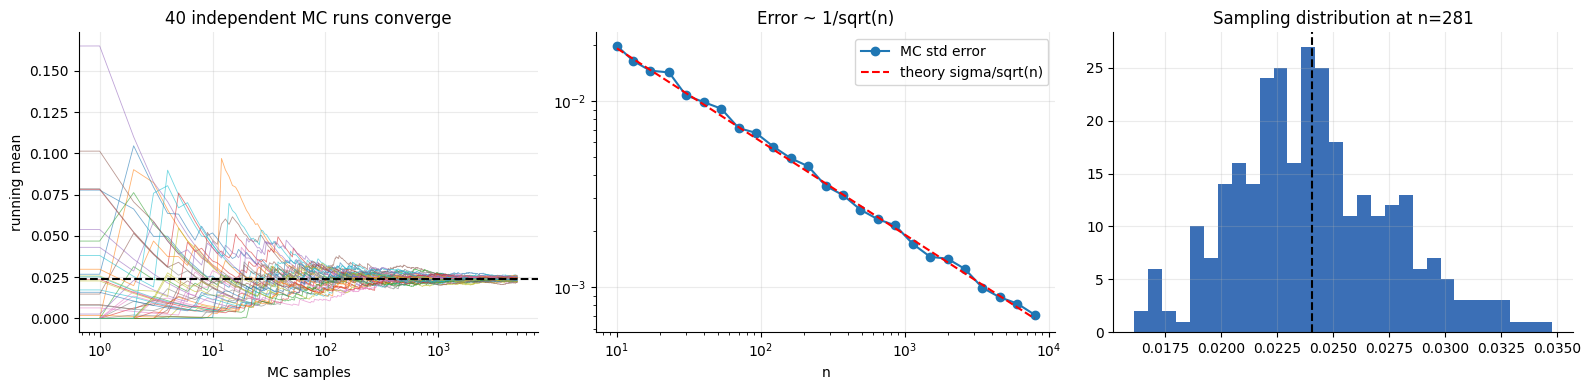

In [2]:
x = f.proxy_bldg_gap.dropna().values; truth = x.mean()
ns = np.unique(np.logspace(1, 3.9, 25).astype(int))
est = np.array([[rng.choice(x, n).mean() for _ in range(300)] for n in ns])        # 300 repeated MC experiments per n
se = est.std(axis=1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for j in range(40): ax[0].plot(np.cumsum(rng.choice(x, 5000)) / np.arange(1, 5001), lw=.6, alpha=.6)
ax[0].axhline(truth, color="k", ls="--"); ax[0].set(xscale="log", xlabel="MC samples", ylabel="running mean", title="40 independent MC runs converge")
ax[1].loglog(ns, se, "o-", label="MC std error"); ax[1].loglog(ns, x.std() / np.sqrt(ns), "r--", label="theory sigma/sqrt(n)"); ax[1].legend(); ax[1].set_xlabel("n"); ax[1].set_title("Error ~ 1/sqrt(n)")
ax[2].hist(est[len(ns) // 2], bins=30, color="#3b6fb6"); ax[2].axvline(truth, color="k", ls="--"); ax[2].set_title(f"Sampling distribution at n={ns[len(ns) // 2]}")
plt.tight_layout(); plt.show()

**Comment:** the simulated standard error follows sigma/sqrt(n) exactly; to halve the error you need four times the draws. The sampling distribution is bell-shaped even though the data are zero-spiked (CLT).

## 2 · Monte Carlo inference on real tracts: permutation test and bootstrap CI
Is the tribal vs non-tribal difference in `y_poi` bigger than chance? Shuffle the labels 10,000 times.

observed difference = -0.397   permutation p = 0.0001   bootstrap 95% CI = [-0.458, -0.333]


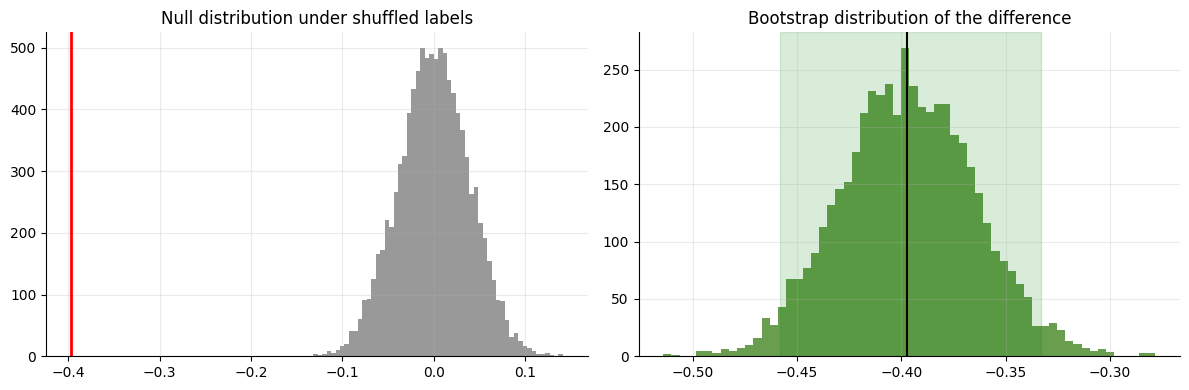

In [3]:
s = f.dropna(subset=["y_poi"]); a = s[s.tribal == 1].y_poi.values; b = s[s.tribal == 0].y_poi.values
obs = a.mean() - b.mean(); allv = np.r_[a, b]; na = len(a)
perm = np.empty(10000)
for i in range(10000):
    p_ = rng.permutation(allv); perm[i] = p_[:na].mean() - p_[na:].mean()
pval = (np.sum(np.abs(perm) >= abs(obs)) + 1) / (len(perm) + 1)
boot = np.array([rng.choice(a, na).mean() - rng.choice(b, len(b)).mean() for _ in range(5000)]); lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"observed difference = {obs:+.3f}   permutation p = {pval:.4f}   bootstrap 95% CI = [{lo:+.3f}, {hi:+.3f}]")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(perm, bins=60, color="#999"); ax[0].axvline(obs, color="r", lw=2); ax[0].set_title("Null distribution under shuffled labels")
ax[1].hist(boot, bins=60, color="#6a9e4f"); ax[1].axvline(obs, color="k"); ax[1].axvspan(lo, hi, color="g", alpha=.15); ax[1].set_title("Bootstrap distribution of the difference")
plt.tight_layout(); plt.show()

**Comment:** the observed gap sits far outside the shuffled-label distribution (p at the floor of what 10,000 draws can resolve), and the bootstrap CI excludes 0. Statistical significance here says nothing about *cause*: that comes in notebooks 11-13.

## 3 · Simulating how the hidden target is built (pure simulation, assumptions labelled)

The organisers' score is the mean of the components that are **defined** for a tract. Zindi reports the share of tracts with at least one undefined component: OK 21%, CA 37%, TX 28%, AZ 55%. We cannot see the true components, so we simulate plausible ones and ask: *what RMSE does the best constant predictor get, and how does it depend on the undefined share?*

Assumptions (not data): each component is zero-inflated (64% exactly 0, matching our building proxy) with the rest ~ Beta(1.2, 9); components are independent; each is defined with probability q, where 1-q^3 matches the reported share.

                  RMSE constant predictor  RMSE (sd across sims)  tracts kept
eastern-ok                         0.0492                 0.0016       0.9995
northern-ca                        0.0521                 0.0026       0.9969
south-central-tx                   0.0507                 0.0008       0.9989
maricopa-az                        0.0563                 0.0021       0.9874


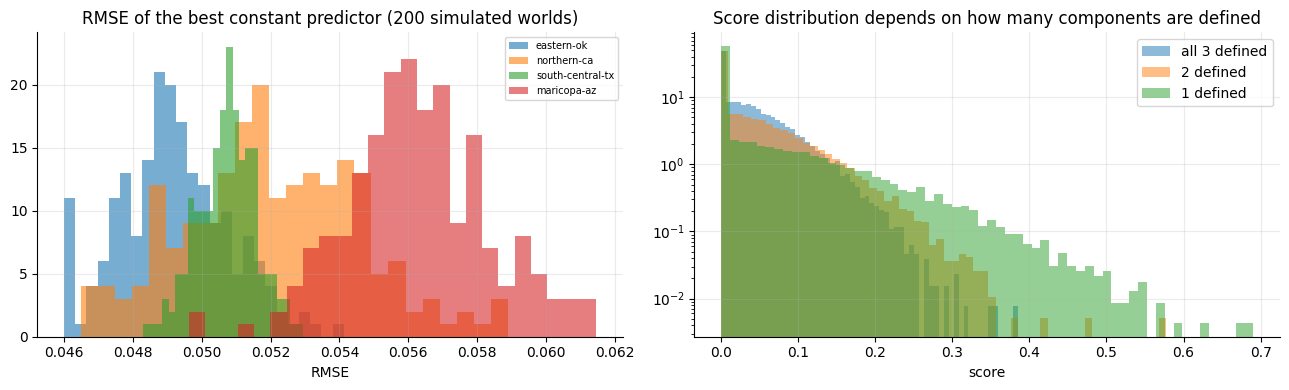

In [4]:
shares = {"eastern-ok": .21, "northern-ca": .37, "south-central-tx": .28, "maricopa-az": .55}
n_t = {"eastern-ok": 1192, "northern-ca": 591, "south-central-tx": 6003, "maricopa-az": 1593}
def simulate(region, reps=200):
    q = (1 - shares[region]) ** (1 / 3); n = n_t[region]; out = []
    for _ in range(reps):
        comp = np.where(rng.random((n, 3)) < .64, 0.0, rng.beta(1.2, 9, (n, 3)))
        defined = rng.random((n, 3)) < q; keep = defined.any(axis=1)
        score = (comp * defined).sum(1)[keep] / defined.sum(1)[keep]
        d_ = defined[keep]
        out.append((rmse(np.full(keep.sum(), score.mean()), score), keep.mean()))      # best constant predictor
    return np.array(out)
res = {r: simulate(r) for r in shares}
tab = pd.DataFrame({r: {"RMSE constant predictor": v[:, 0].mean(), "RMSE (sd across sims)": v[:, 0].std(), "tracts kept": v[:, 1].mean()} for r, v in res.items()}).T
print(tab.round(4).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r, v in res.items(): ax[0].hist(v[:, 0], bins=25, alpha=.6, label=r)
ax[0].legend(fontsize=7); ax[0].set_title("RMSE of the best constant predictor (200 simulated worlds)"); ax[0].set_xlabel("RMSE")
comp = np.where(rng.random((20000, 3)) < .64, 0.0, rng.beta(1.2, 9, (20000, 3)))
for r, c in zip(["all 3 defined", "2 defined", "1 defined"], [3, 2, 1]):
    ax[1].hist(comp[:, :c].mean(1), bins=60, alpha=.5, label=r, density=True)
ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title("Score distribution depends on how many components are defined"); ax[1].set_xlabel("score")
plt.tight_layout(); plt.show()

**Comment:** averaging fewer components leaves the score more spread out and lumpier (exact zeros are more common and the extremes larger), so the constant-predictor RMSE grows with the undefined share (largest for Maricopa at 55%). In this simulation components are identical, so definedness changes only the *spread*; in the real data components differ (transport vs building vs POI), so which components are defined would also shift the mean. These numbers illustrate the mechanism; they are not estimates of the real leaderboard.

## 4 · MCMC: Metropolis-Hastings for a Bayesian logistic regression
Posterior for P(no fire POI) with standardised log-area and log-density, priors N(0, 10^2). Three chains, random-walk proposals.

acceptance rates: [0.28, 0.28, 0.28]
               MLE  posterior mean  post sd  R-hat
intercept    0.956           0.956    0.025  1.000
log_area    -0.978          -0.985    0.086  1.009
log_density -0.276          -0.283    0.085  1.010


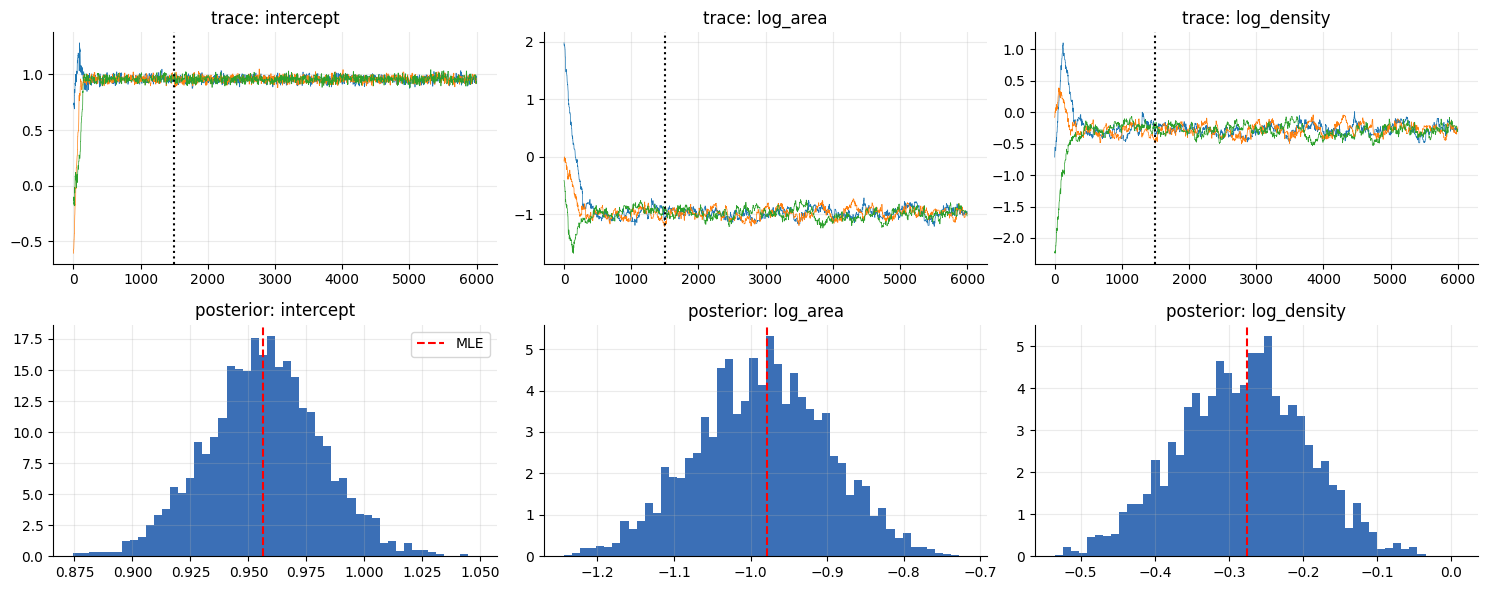

In [5]:
s = f.dropna(subset=["log_pop_density", "log_area_km2"])
Xm = np.c_[np.ones(len(s)), (s.log_area_km2 - s.log_area_km2.mean()) / s.log_area_km2.std(), (s.log_pop_density - s.log_pop_density.mean()) / s.log_pop_density.std()]
ym = s.no_fire.values
def logpost(w):
    z = Xm @ w
    return np.sum(ym * z - np.logaddexp(0, z)) - np.sum(w ** 2) / (2 * 10 ** 2)
mle = sm.Logit(ym, Xm).fit(disp=0)
def mh(n=6000, step=.04, w0=None):
    w = np.zeros(3) if w0 is None else w0.copy(); lp = logpost(w); chain = np.empty((n, 3)); acc = 0
    for i in range(n):
        prop = w + step * rng.standard_normal(3); lpp = logpost(prop)
        if np.log(rng.random()) < lpp - lp: w, lp = prop, lpp; acc += 1
        chain[i] = w
    return chain, acc / n
chains = [mh(w0=rng.normal(0, 1, 3)) for _ in range(3)]
burn = 1500; post = np.vstack([c[burn:] for c, _ in chains])
def rhat(cs):
    m, n = len(cs), len(cs[0]); means = np.array([c.mean() for c in cs]); B = n * means.var(ddof=1); W = np.mean([c.var(ddof=1) for c in cs])
    return np.sqrt(((n - 1) / n * W + B / n) / W)
names = ["intercept", "log_area", "log_density"]
print("acceptance rates:", [round(a, 2) for _, a in chains])
print(pd.DataFrame({"MLE": mle.params, "posterior mean": post.mean(0), "post sd": post.std(0), "R-hat": [rhat([c[burn:, j] for c, _ in chains]) for j in range(3)]}, index=names).round(3).to_string())
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for j in range(3):
    for c, _ in chains: ax[0, j].plot(c[:, j], lw=.5)
    ax[0, j].axvline(burn, color="k", ls=":"); ax[0, j].set_title(f"trace: {names[j]}")
    ax[1, j].hist(post[:, j], bins=50, density=True, color="#3b6fb6"); ax[1, j].axvline(mle.params[j], color="r", ls="--", label="MLE"); ax[1, j].set_title(f"posterior: {names[j]}")
ax[1, 0].legend(); plt.tight_layout(); plt.show()

**Comment:** chains started at random points converge to the same region (R-hat near 1), the posterior means match the classical maximum-likelihood estimates, and the posterior widths are the uncertainty a point estimate hides. MCMC earns its keep for models without a closed-form fit; here logistic regression is the sanity check.